# Parameter Grid Reliability: Smoothing × Motion Censoring
- Analyzes `coordinatesAll_param.csv`: multi-echo (`me`) data rebuilt over a grid of preprocessing parameters by `x07.blur_censor_param.csh`.
- Grid: smoothing kernel `-FWHM` {0, 2, 4, 6} mm × motion censor limit {0.15, 0.3, 0.45}.
- Encoded in `runTag` as `param-b{FWHM}m{motion}` ('.' -> 'p'), e.g. `param-b4m0p3` -> FWHM 4 mm, motion 0.3.
- Compares reliability (mean pairwise distance between sessions) across FWHM and motion limit, then tests whether they interact with each other and with the target / cluster mask choices from `main.ipynb`.

In [ ]:
import os
import itertools
import pandas as pd
import numpy as np

from scipy.spatial.distance import pdist
from statsmodels.stats.anova import AnovaRM

# Plotting Packages
import seaborn as sns
import matplotlib.pyplot as plt
import configFunctions as config
from statFunctions import rm_test, print_rm_test, raincloud, format_pairwise, PAIRWISE_HEADER

# Variables
dataFile = 'coordinatesAll_param.csv' # Path to the CSV file containing the parameter grid coordinates

# Peak search to analyze: 'abs' matches main.ipynb (|z| peak); 'pos' / 'neg' are signed peaks.
# In line with original analysis, we will use the absolute value of the peak for this analysis.
peakSign = 'abs'

# Only keep sessions present in every grid cell, so each mean distance is built from the same sessions.
matchSessions = True

# Levels expected from x07.blur_censor_param.csh; checked against the data after decoding.
expectedGrid = {'fwhm': [0, 2, 4, 6], 'motion': [0.15, 0.3, 0.45]}

# Output directory
output_dir = os.path.join('output', 'paramGrid')
os.makedirs(output_dir, exist_ok=True)

### Required files
- `coordinatesAll_param.csv` - generated by serverFunctions, final output of mergeOutputs, one row per session × variant identified by `runTag`.

In [2]:
# A configuration function to make output images easier to modify for publication.
config.svg_editing()

In [3]:
# load data, inspect (subject/session as strings so leading zeros survive)
df = pd.read_csv(dataFile, dtype={'subject': str, 'session': str})
print(f'{len(df)} rows, {df["subject"].nunique()} subjects')
print(df['sign'].value_counts().to_string())
df.head()

81366 rows, 87 subjects
sign
abs    27282
pos    27042
neg    27042


,filename,filepath,subject,session,task,sequence_type,runTag,target,sign,clustRegion,clustMask,X,Y,Z,peakZ
0,068.04.rest.me.param-b4m0p3.errts.targ.seed.fi...,/cbica/projects/nbthetaconn/pipeline/results/0...,068,04,rest,me,param-b4m0p3,seed,abs,ldlpfc,orig,39.0,-41.0,35.0,0.1960
1,068.02.rest.me.param-b4m0p3.errts.targ.network...,/cbica/projects/nbthetaconn/pipeline/results/0...,068,02,rest,me,param-b4m0p3,network,abs,ldlpfc,dilate_5,23.0,-45.0,39.0,0.5729
2,068.04.rest.me.param-b0m0p3.errts.targ.seed.fi...,/cbica/projects/nbthetaconn/pipeline/results/0...,068,04,rest,me,param-b0m0p3,seed,abs,ldlpfc,erode_1,35.0,-33.0,33.0,0.1111
3,068.03.rest.me.param-b4m0p15.errts.targ.networ...,/cbica/projects/nbthetaconn/pipeline/results/0...,068,03,rest,me,param-b4m0p15,network,pos,ldlpfc,dilate_5,25.0,-27.0,49.0,0.6043
4,068.04.rest.me.param-b0m0p45.errts.targ.seed.f...,/cbica/projects/nbthetaconn/pipeline/results/0...,068,04,rest,me,param-b0m0p45,seed,pos,ldlpfc,dilate_5,23.0,-43.0,37.0,0.2214


### Intermediate clean up
- Keep only the selected peak sign.
- Keep only the grid variants (`param-b{F}m{M}`). Dropped:
  - `param` - the base afni_proc run (FWHM 4, motion 0.3). `param-b4m0p3` repeats its settings, so it would double that grid cell.
  - Untagged rows (empty `runTag`) - older runs that predate the grid.
- Decode `fwhm` and `motion` from the run tag, and check the levels against `expectedGrid`.

In [4]:
df = df[df['sign'] == peakSign].copy()

# Decode 'param-b4m0p3' -> fwhm 4, motion 0.3; other tags (base 'param', untagged) become NaN
parsed = df['runTag'].str.extract(r'-b(?P<fwhm>\d+)m(?P<motion>\d+p\d+)$')
df['fwhm'] = parsed['fwhm'].astype(float)
df['motion'] = parsed['motion'].str.replace('p', '.').astype(float)

print('Rows dropped (not a grid variant):')
print(df.loc[df['fwhm'].isna(), 'runTag'].fillna('<untagged>').value_counts().to_string())
df = df[df['fwhm'].notna()].copy()

for var, expected in expectedGrid.items():
    found = sorted(df[var].unique())
    assert found == expected, f'{var} levels {found} do not match expectedGrid {expected}'

print(f"\nsign = '{peakSign}': {len(df)} rows remaining")
pd.crosstab(df['fwhm'], df['motion'])

Rows dropped (not a grid variant):
runTag
param         2082
<untagged>     240

sign = 'abs': 24960 rows remaining


motion,0.15,0.30,0.45
fwhm,,,
0.0,2076,2082,2082
2.0,2076,2082,2082
4.0,2076,2082,2082
6.0,2076,2082,2082


In [5]:
# Pull out and show the rows which include any nans (peakZ excluded - missing peaks also lack X/Y/Z)
rows_with_nan = df[df[['X', 'Y', 'Z']].isna().any(axis=1)]

# Save them if desired
# rows_with_nan.to_csv(os.path.join(output_dir, 'coordinatesParam_NaNRows.csv'), index=False)

# Read out
subj_with_nan = rows_with_nan['subject'].unique()
print(f'Subjects with NaNs - {len(subj_with_nan)}')
print(f'List: {list(subj_with_nan)}')

# Remove subjects with NaNs.
df = df[~df['subject'].isin(subj_with_nan)]

# Sessions missing from some grid cells (e.g. a motion limit skipped for too few TRs)
cellVars = ['fwhm', 'motion', 'target', 'clustMask']
nCells = df[cellVars].drop_duplicates().shape[0]
sesCells = df.groupby(['subject', 'session'])[cellVars].apply(lambda g: len(g.drop_duplicates()))
partialSes = sesCells[sesCells < nCells]
print(f'\nSessions missing grid cells ({nCells} expected):')
print(partialSes.to_string() if len(partialSes) else '  none')

if matchSessions and len(partialSes):
    dropIdx = pd.MultiIndex.from_frame(df[['subject', 'session']]).isin(partialSes.index)
    df = df[~dropIdx]
    print(f'Dropped {dropIdx.sum()} rows from those sessions')

print(f"\n{len(df['subject'].unique())} Subjects Remaining...")

Subjects with NaNs - 0
List: []

Sessions missing grid cells (72 expected):
subject  session
100      03         48
Dropped 48 rows from those sessions

87 Subjects Remaining...


### Mean pairwise distance per subject × condition
- For each subject × FWHM × motion × target mask × cluster mask, the mean Euclidean distance across sessions.
- Subjects with fewer than 2 sessions in any cell (no distance to compute) and subjects missing cells (`AnovaRM` needs a full design) are dropped.

In [ ]:
grouping_vars = ['subject', 'fwhm', 'motion', 'target', 'clustMask']

def session_distance(g):
    dists = pdist(g[['X', 'Y', 'Z']].values, metric='euclidean')
    return pd.Series({'n_sessions': len(g),
                      'mean_distance': round(dists.mean(), 2) if len(dists) else np.nan})

combodf = (df.groupby(grouping_vars).apply(session_distance, include_groups=False).reset_index())
combodf['n_sessions'] = combodf['n_sessions'].astype(int)

print('Sessions per cell:')
print(combodf['n_sessions'].value_counts().sort_index().to_string())

singleSes = combodf.loc[combodf['n_sessions'] < 2, 'subject'].unique().tolist()
if singleSes:
    print(f'Dropping {len(singleSes)} subjects with < 2 sessions in some cell: {singleSes}')
    combodf = combodf[~combodf['subject'].isin(singleSes)]

# AnovaRM needs every subject in every cell
nCells = combodf[grouping_vars[1:]].drop_duplicates().shape[0]
cellsPerSubj = combodf.groupby('subject').size()
incomplete = cellsPerSubj[cellsPerSubj < nCells].index.tolist()
if incomplete:
    print(f'Dropping {len(incomplete)} subjects with incomplete cells: {incomplete}')
    combodf = combodf[~combodf['subject'].isin(incomplete)]

combodf = combodf.reset_index(drop=True)
combodf.to_csv(os.path.join(output_dir, 'combodf_param.csv'), index=False)
print(f"{combodf['subject'].nunique()} subjects x {nCells} cells")
combodf.head()

Sessions per cell:
n_sessions
3     144
4    6120
87 subjects x 72 cells


,subject,fwhm,motion,target,clustMask,n_sessions,mean_distance
0,001,0.0,0.15,network,dilate_5,4,20.09
1,001,0.0,0.15,network,erode_1,4,7.92
2,001,0.0,0.15,network,orig,4,6.09
3,001,0.0,0.15,seed,dilate_5,4,23.29
4,001,0.0,0.15,seed,erode_1,4,10.31


# Plotting

In [8]:
targetName = 'sgACC' # For plotting, what does the 'target' mask represent?
clusterRegion = 'dlPFC' # for plotting, what does the 'clusterMask' mask represent?

# Grid factors (this notebook's focus); target and clustMask are carried over from main.ipynb
gridVars = ['fwhm', 'motion']

orderDict = {
    'fwhm': sorted(combodf['fwhm'].unique()),
    'motion': sorted(combodf['motion'].unique()),
    'target': ['seed', 'network'],
    'clustMask': ['erode_1', 'orig', 'dilate_5'],
}
nameDict = {
    'fwhm': [f'{b:g} mm' if b else 'None' for b in orderDict['fwhm']],
    'motion': [f'{m:g} mm' for m in orderDict['motion']],
    'target': ['Seed', 'Network'],
    'clustMask': ['Eroded', 'Original', 'Dilated'],
}
varNameDict = {'fwhm': 'Smoothing Kernel (FWHM)', 'motion': 'Motion Censor Limit',
               'target': f'{targetName} mask', 'clustMask': f'{clusterRegion} mask'}

ylabel = 'Mean Pairwise Distance (mm)'

## Main effects: smoothing kernel and motion censor limit
- For each factor, average across all other factors so each subject has one value per level, then run a one-way RM-ANOVA with Bonferroni post-hoc paired t-tests (as in `main.ipynb`).
- Helpers (`rm_test`, `raincloud`, significance brackets) live in `statFunctions.py`.

In [9]:
stat_results = {}
agg_dfs = {}

for var in gridVars:
    agg_dfs[var] = combodf.groupby(['subject', var])['mean_distance'].mean().reset_index()
    stat_results[var] = rm_test(agg_dfs[var], var, orderDict[var])
    print_rm_test(stat_results[var], varNameDict[var])
    print()

Smoothing Kernel (FWHM): RM-ANOVA, F=0.975, p=4.05e-01
  Post-hoc paired t-tests (Bonferroni corrected, k=6):
    Comparison        mean_diff          t        p_raw       p_corr   sig
    0 vs 2                0.054     -0.391     6.97e-01     1.00e+00      
    0 vs 4                0.241     -1.081     2.83e-01     1.00e+00      
    0 vs 6                0.313     -1.123     2.65e-01     1.00e+00      
    2 vs 4                0.187     -1.151     2.53e-01     1.00e+00      
    2 vs 6                0.259     -1.065     2.90e-01     1.00e+00      
    4 vs 6                0.072     -0.358     7.21e-01     1.00e+00      

Motion Censor Limit: RM-ANOVA, F=2.534, p=8.23e-02
  Post-hoc paired t-tests (Bonferroni corrected, k=3):
    Comparison        mean_diff          t        p_raw       p_corr   sig
    0.15 vs 0.3          -0.226      1.550     1.25e-01     3.74e-01      
    0.15 vs 0.45         -0.277      1.694     9.38e-02     2.81e-01      
    0.3 vs 0.45          -0.051  

### Raincloud plot - main effects

Do a raincloud plot where the variable of interest in examined. Average across all the other conditions such that each subject produces a single mean distance metric across all analyses.

C:\Users\aboha\AppData\Local\Temp\ipykernel_27400\2349813868.py:6: UserWarning: The figure layout has changed to tight
  plt.tight_layout()


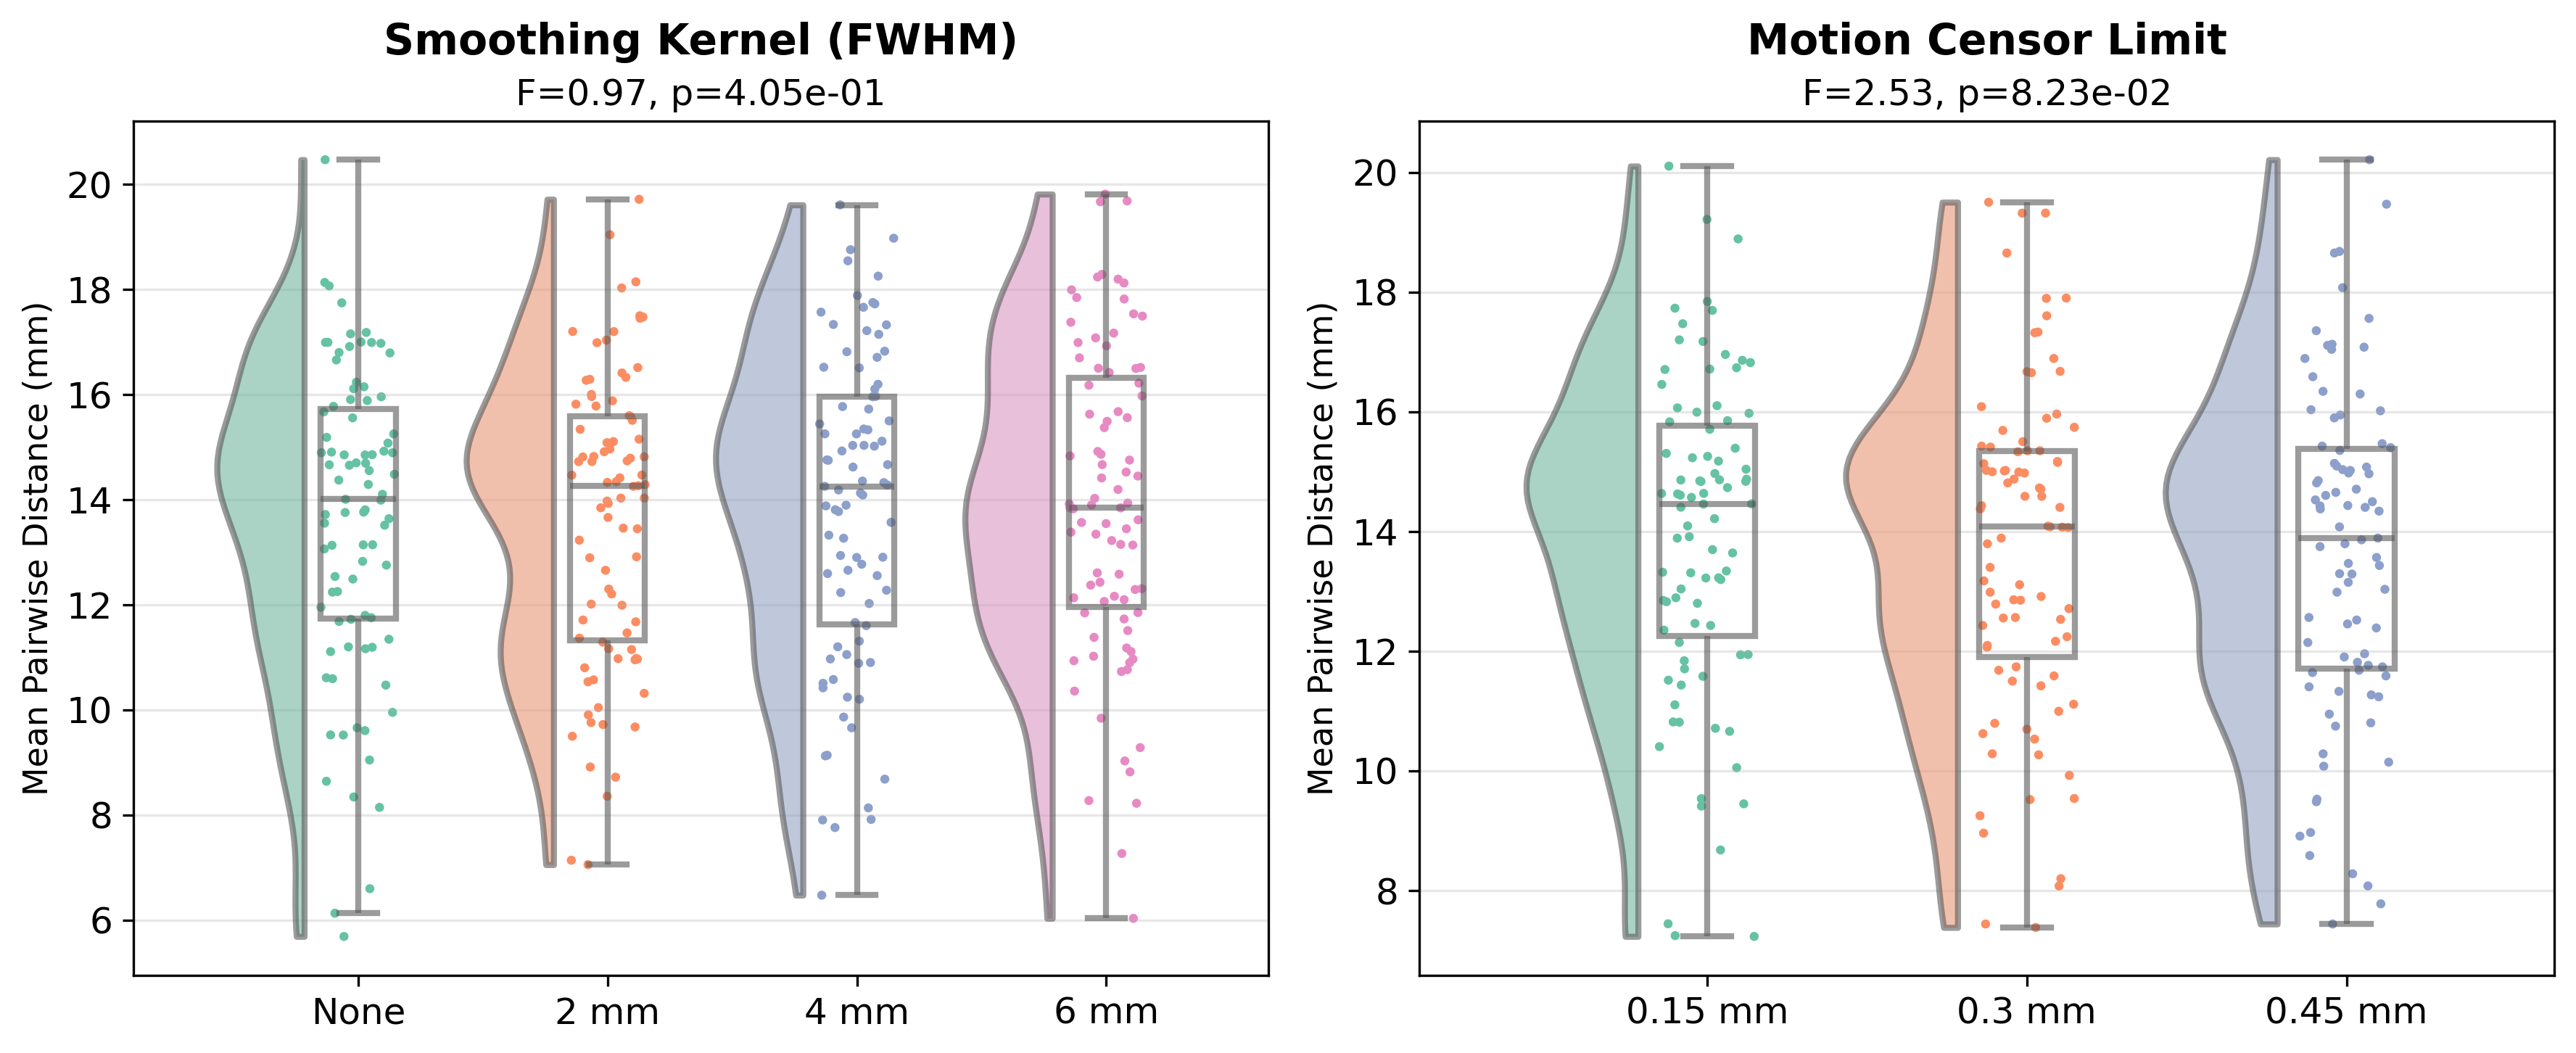

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

for ax, var in zip(axes, gridVars):
    raincloud(ax, agg_dfs[var], var, orderDict[var], nameDict[var], stat_results[var], varNameDict[var], ylabel)

plt.tight_layout()
plt.savefig(os.path.join(output_dir, 'Rainplot_fwhm_motion.svg'))
plt.show()

# Interaction: smoothing kernel × motion censor limit
- 2-way RM-ANOVA on the subject × FWHM × motion means (averaged over target and cluster mask).
- 4-way RM-ANOVA on the full design, to check whether either grid factor interacts with the target or cluster mask choice from `main.ipynb`.
- Note: `AnovaRM` reports uncorrected (sphericity-assumed) p-values.

In [11]:
fwhmMotion_df = combodf.groupby(['subject', 'fwhm', 'motion'])['mean_distance'].mean().reset_index()

res_2way = AnovaRM(data=fwhmMotion_df, depvar='mean_distance', subject='subject',
                   within=['fwhm', 'motion']).fit()
print('2-Way Repeated Measures ANOVA (fwhm x motion)')
print('=' * 60)
print(res_2way)
twoway_table = res_2way.anova_table

2-Way Repeated Measures ANOVA (fwhm x motion)
                  Anova
            F Value Num DF  Den DF  Pr > F
------------------------------------------
fwhm         0.9749 3.0000 258.0000 0.4051
motion       2.5342 2.0000 172.0000 0.0823
fwhm:motion  0.8478 6.0000 516.0000 0.5334



In [12]:
res_4way = AnovaRM(data=combodf, depvar='mean_distance', subject='subject',
                   within=['fwhm', 'motion', 'target', 'clustMask']).fit()
print('4-Way Repeated Measures ANOVA (fwhm x motion x target x clustMask)')
print('=' * 60)
print(res_4way)
fourway_table = res_4way.anova_table

4-Way Repeated Measures ANOVA (fwhm x motion x target x clustMask)
                            Anova
                             F Value   Num DF   Den DF  Pr > F
--------------------------------------------------------------
fwhm                           0.9749  3.0000  258.0000 0.4051
motion                         2.5342  2.0000  172.0000 0.0823
target                        38.5618  1.0000   86.0000 0.0000
clustMask                    266.8368  2.0000  172.0000 0.0000
fwhm:motion                    0.8478  6.0000  516.0000 0.5334
fwhm:target                    0.1530  3.0000  258.0000 0.9277
motion:target                  0.0045  2.0000  172.0000 0.9956
fwhm:clustMask                 1.1362  6.0000  516.0000 0.3398
motion:clustMask               5.7447  4.0000  344.0000 0.0002
target:clustMask               6.3255  2.0000  172.0000 0.0022
fwhm:motion:target             0.8323  6.0000  516.0000 0.5453
fwhm:motion:clustMask          0.4133 12.0000 1032.0000 0.9589
fwhm:target:clust

### Interaction plot
- Cell means ± SEM across subjects. Parallel lines = no interaction; converging/crossing lines = the effect of one factor depends on the other.
- Heatmap shows the same cell means on the grid.

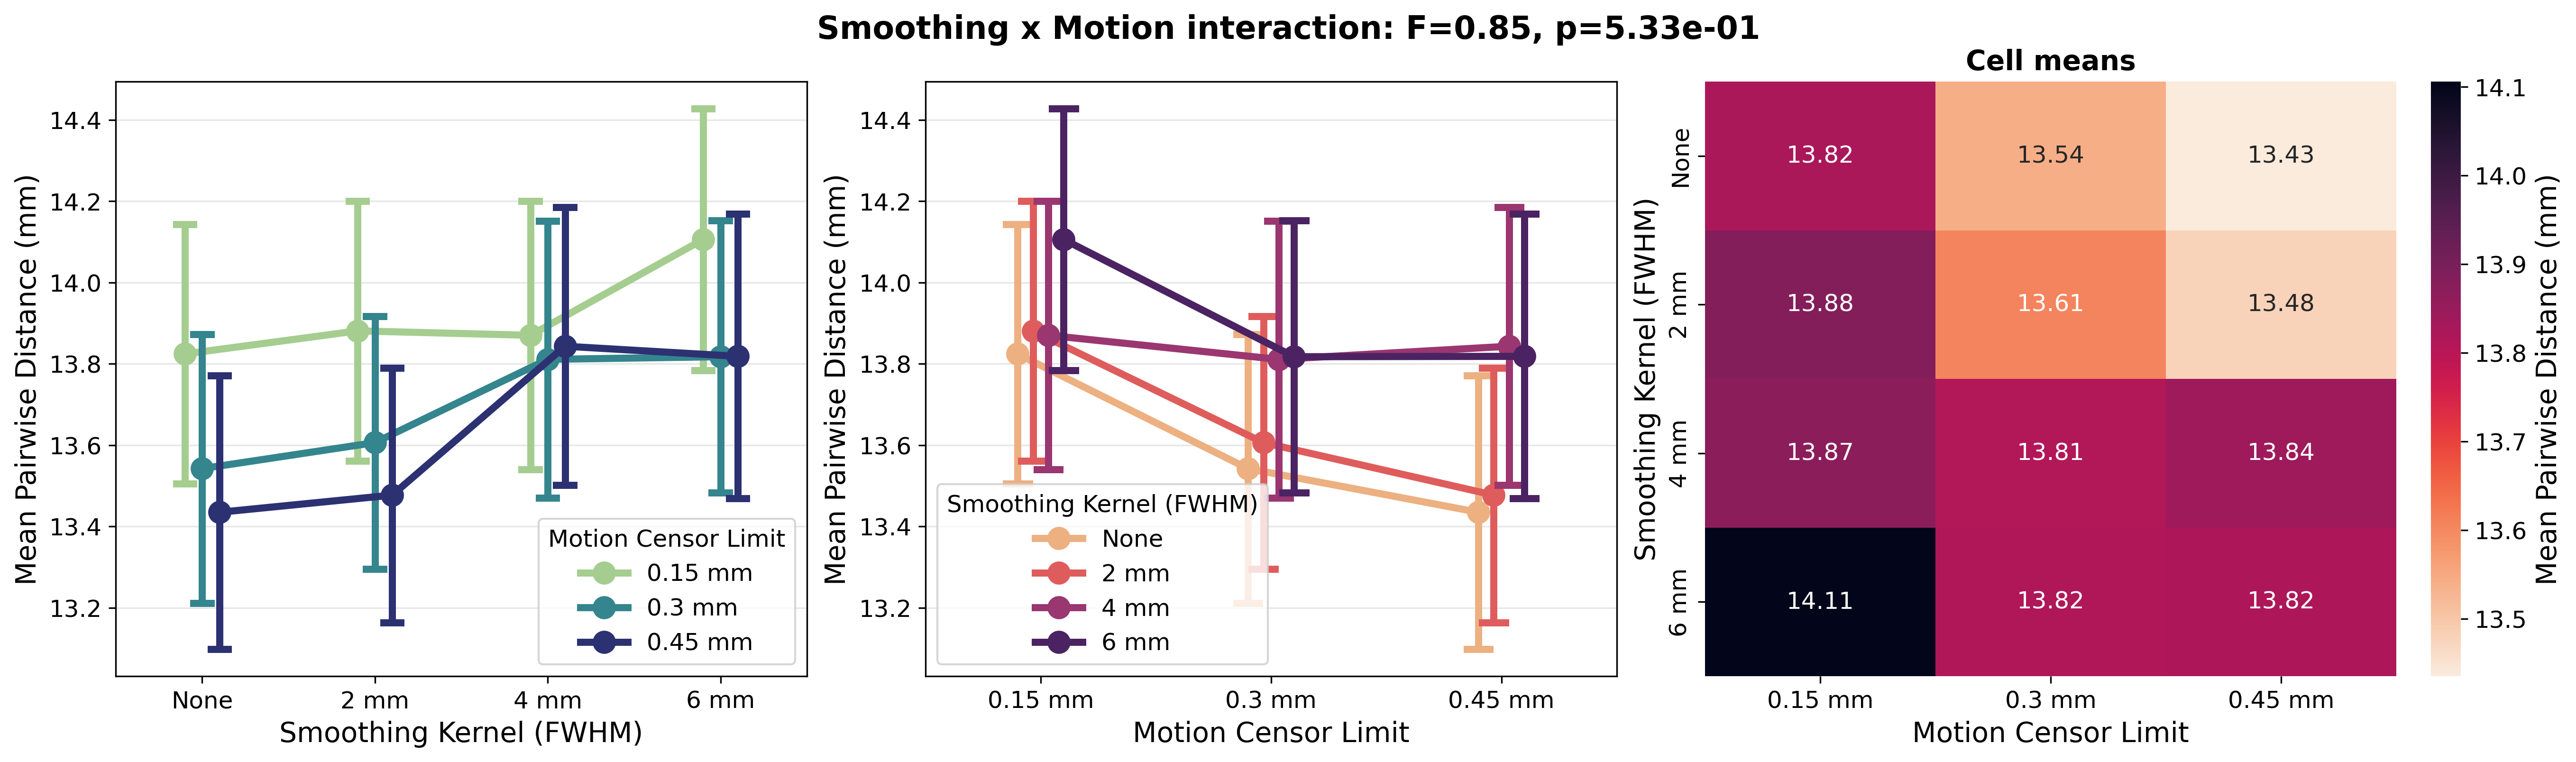

In [13]:
inter_p = twoway_table.loc['fwhm:motion', 'Pr > F']
inter_F = twoway_table.loc['fwhm:motion', 'F Value']

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# FWHM on x, one line per motion limit
sns.pointplot(data=fwhmMotion_df, x='fwhm', y='mean_distance', hue='motion', order=orderDict['fwhm'],
              hue_order=orderDict['motion'], palette='crest', errorbar='se', dodge=0.2,
              capsize=0.1, ax=axes[0])
axes[0].set_xticks(range(len(orderDict['fwhm'])), nameDict['fwhm'])
axes[0].set_xlabel(varNameDict['fwhm'])
handles, _ = axes[0].get_legend_handles_labels()
axes[0].legend(handles, nameDict['motion'], title=varNameDict['motion'])

# Motion on x, one line per FWHM
sns.pointplot(data=fwhmMotion_df, x='motion', y='mean_distance', hue='fwhm', order=orderDict['motion'],
              hue_order=orderDict['fwhm'], palette='flare', errorbar='se', dodge=0.2,
              capsize=0.1, ax=axes[1])
axes[1].set_xticks(range(len(orderDict['motion'])), nameDict['motion'])
axes[1].set_xlabel(varNameDict['motion'])
handles, _ = axes[1].get_legend_handles_labels()
axes[1].legend(handles, nameDict['fwhm'], title=varNameDict['fwhm'])

for ax in axes[:2]:
    ax.set_ylabel(ylabel)

# Cell-mean heatmap
cellMeans = fwhmMotion_df.pivot_table(index='fwhm', columns='motion', values='mean_distance', aggfunc='mean')
sns.heatmap(cellMeans, annot=True, fmt='.2f', cmap='rocket_r', ax=axes[2],
            xticklabels=nameDict['motion'], yticklabels=nameDict['fwhm'],
            cbar_kws={'label': ylabel})
axes[2].set_xlabel(varNameDict['motion'])
axes[2].set_ylabel(varNameDict['fwhm'])
axes[2].set_title('Cell means', fontsize=14, fontweight='bold')

plt.suptitle(f'Smoothing x Motion interaction: F={inter_F:.2f}, p={inter_p:.2e}', fontsize=16, fontweight='bold', y=1.04)
# No tight_layout here: the heatmap colorbar needs the constrained layout set by config.svg_editing()
plt.savefig(os.path.join(output_dir, 'Interaction_fwhm_motion.svg'))
plt.show()

### Raincloud plots - simple effects
- Effect of smoothing kernel at each motion limit (top row), and of motion limit at each kernel size (bottom row).
- Each panel is its own one-way RM-ANOVA with Bonferroni post-hoc tests; useful for reading where an interaction comes from.

Smoothing Kernel (FWHM) | motion = 0.15: RM-ANOVA, F=0.564, p=6.39e-01
  Post-hoc paired t-tests (Bonferroni corrected, k=6):
    Comparison        mean_diff          t        p_raw       p_corr   sig
    0 vs 2                0.057     -0.344     7.32e-01     1.00e+00      
    0 vs 4                0.046     -0.187     8.52e-01     1.00e+00      
    0 vs 6                0.282     -0.942     3.49e-01     1.00e+00      
    2 vs 4               -0.011      0.060     9.52e-01     1.00e+00      
    2 vs 6                0.225     -0.823     4.13e-01     1.00e+00      
    4 vs 6                0.236     -1.016     3.13e-01     1.00e+00      
Smoothing Kernel (FWHM) | motion = 0.3: RM-ANOVA, F=0.688, p=5.60e-01
  Post-hoc paired t-tests (Bonferroni corrected, k=6):
    Comparison        mean_diff          t        p_raw       p_corr   sig
    0 vs 2                0.064     -0.401     6.89e-01     1.00e+00      
    0 vs 4                0.269     -1.107     2.71e-01     1.00e+00      

C:\Users\aboha\AppData\Local\Temp\ipykernel_27400\31080460.py:25: UserWarning: The figure layout has changed to tight
  plt.tight_layout()


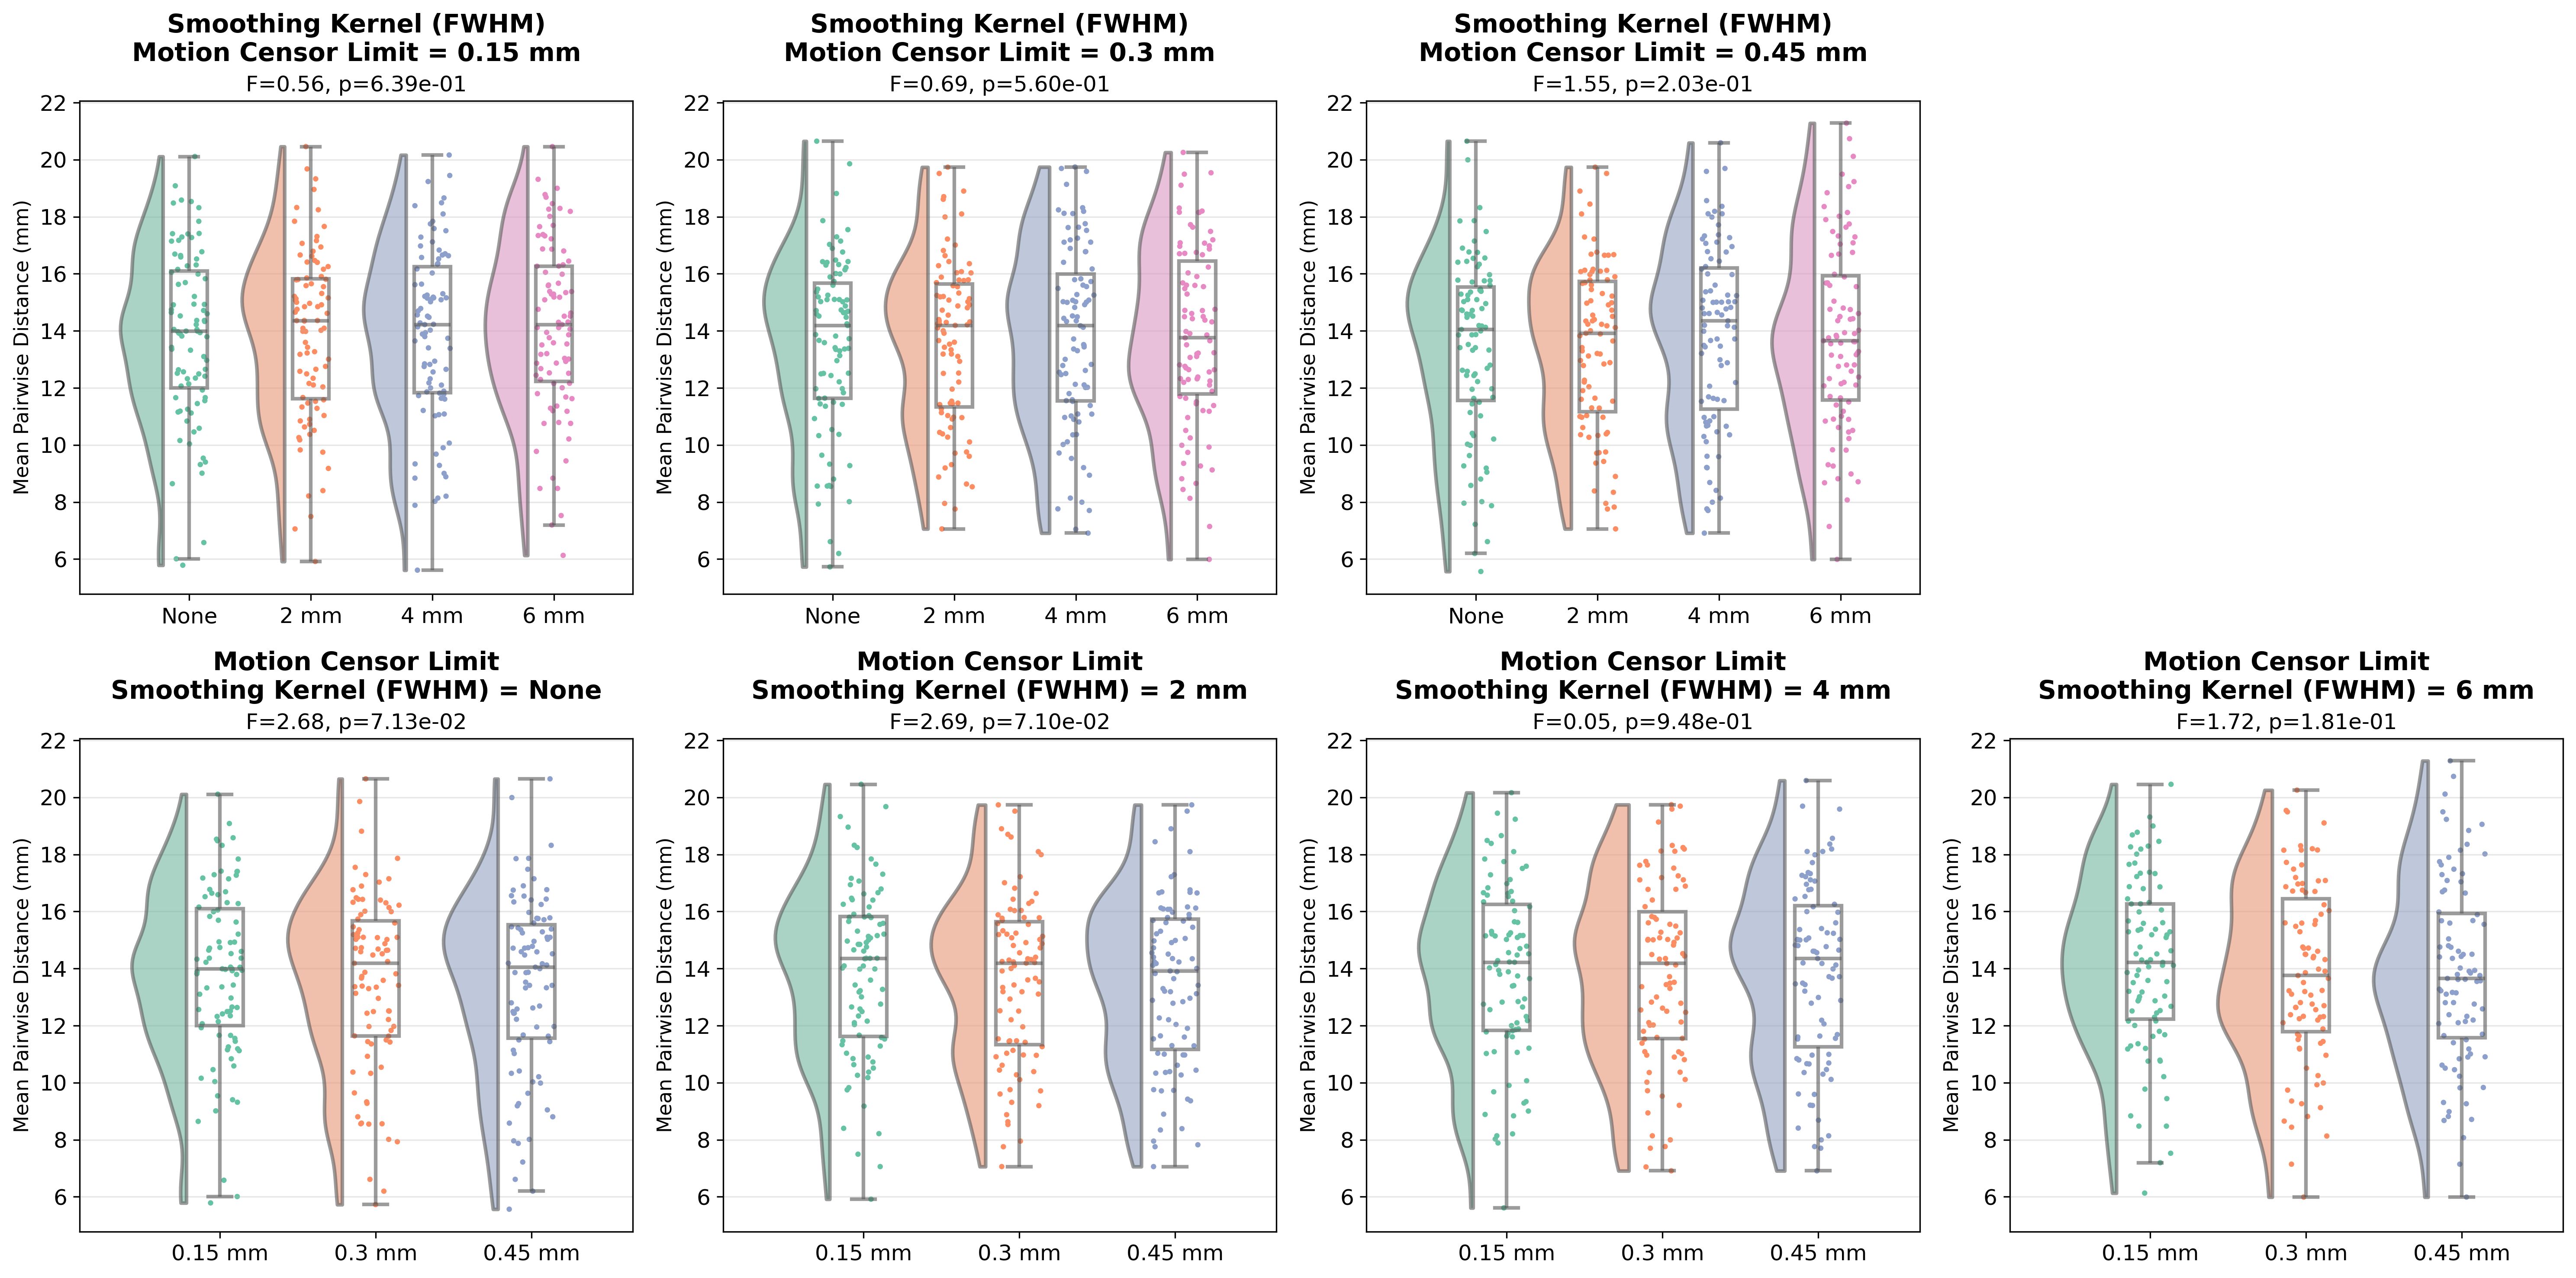

In [14]:
simple_results = {}

nCols = max(len(orderDict['motion']), len(orderDict['fwhm']))
fig, axes = plt.subplots(2, nCols, figsize=(5 * nCols, 10))

# Row 1: FWHM within each motion level. Row 2: motion within each FWHM level.
for row, (testVar, splitVar) in enumerate([('fwhm', 'motion'), ('motion', 'fwhm')]):
    for col, level in enumerate(orderDict[splitVar]):
        sub = fwhmMotion_df[fwhmMotion_df[splitVar] == level]
        result = rm_test(sub, testVar, orderDict[testVar])
        simple_results[(testVar, splitVar, level)] = result
        print_rm_test(result, f'{varNameDict[testVar]} | {splitVar} = {level:g}')
        title = f"{varNameDict[testVar]}\n{varNameDict[splitVar]} = {nameDict[splitVar][col]}"
        raincloud(axes[row, col], sub, testVar, orderDict[testVar], nameDict[testVar], result, title, ylabel)
    for col in range(len(orderDict[splitVar]), nCols):
        axes[row, col].set_visible(False)
    print()

# Shared y-limits so panels are comparable
y_lo = min(ax.get_ylim()[0] for ax in axes.flat if ax.get_visible())
y_hi = max(ax.get_ylim()[1] for ax in axes.flat if ax.get_visible())
for ax in axes.flat:
    ax.set_ylim(y_lo, y_hi)

plt.tight_layout()
plt.savefig(os.path.join(output_dir, 'Rainplot_simple_effects.svg'))
plt.show()

### Interactions with target and cluster mask
- Cell means for each grid factor split by the `main.ipynb` factors, to visualize the grid × target / clustMask terms from the 4-way model.

C:\Users\aboha\AppData\Local\Temp\ipykernel_27400\2125548316.py:21: UserWarning: The figure layout has changed to tight
  plt.tight_layout()


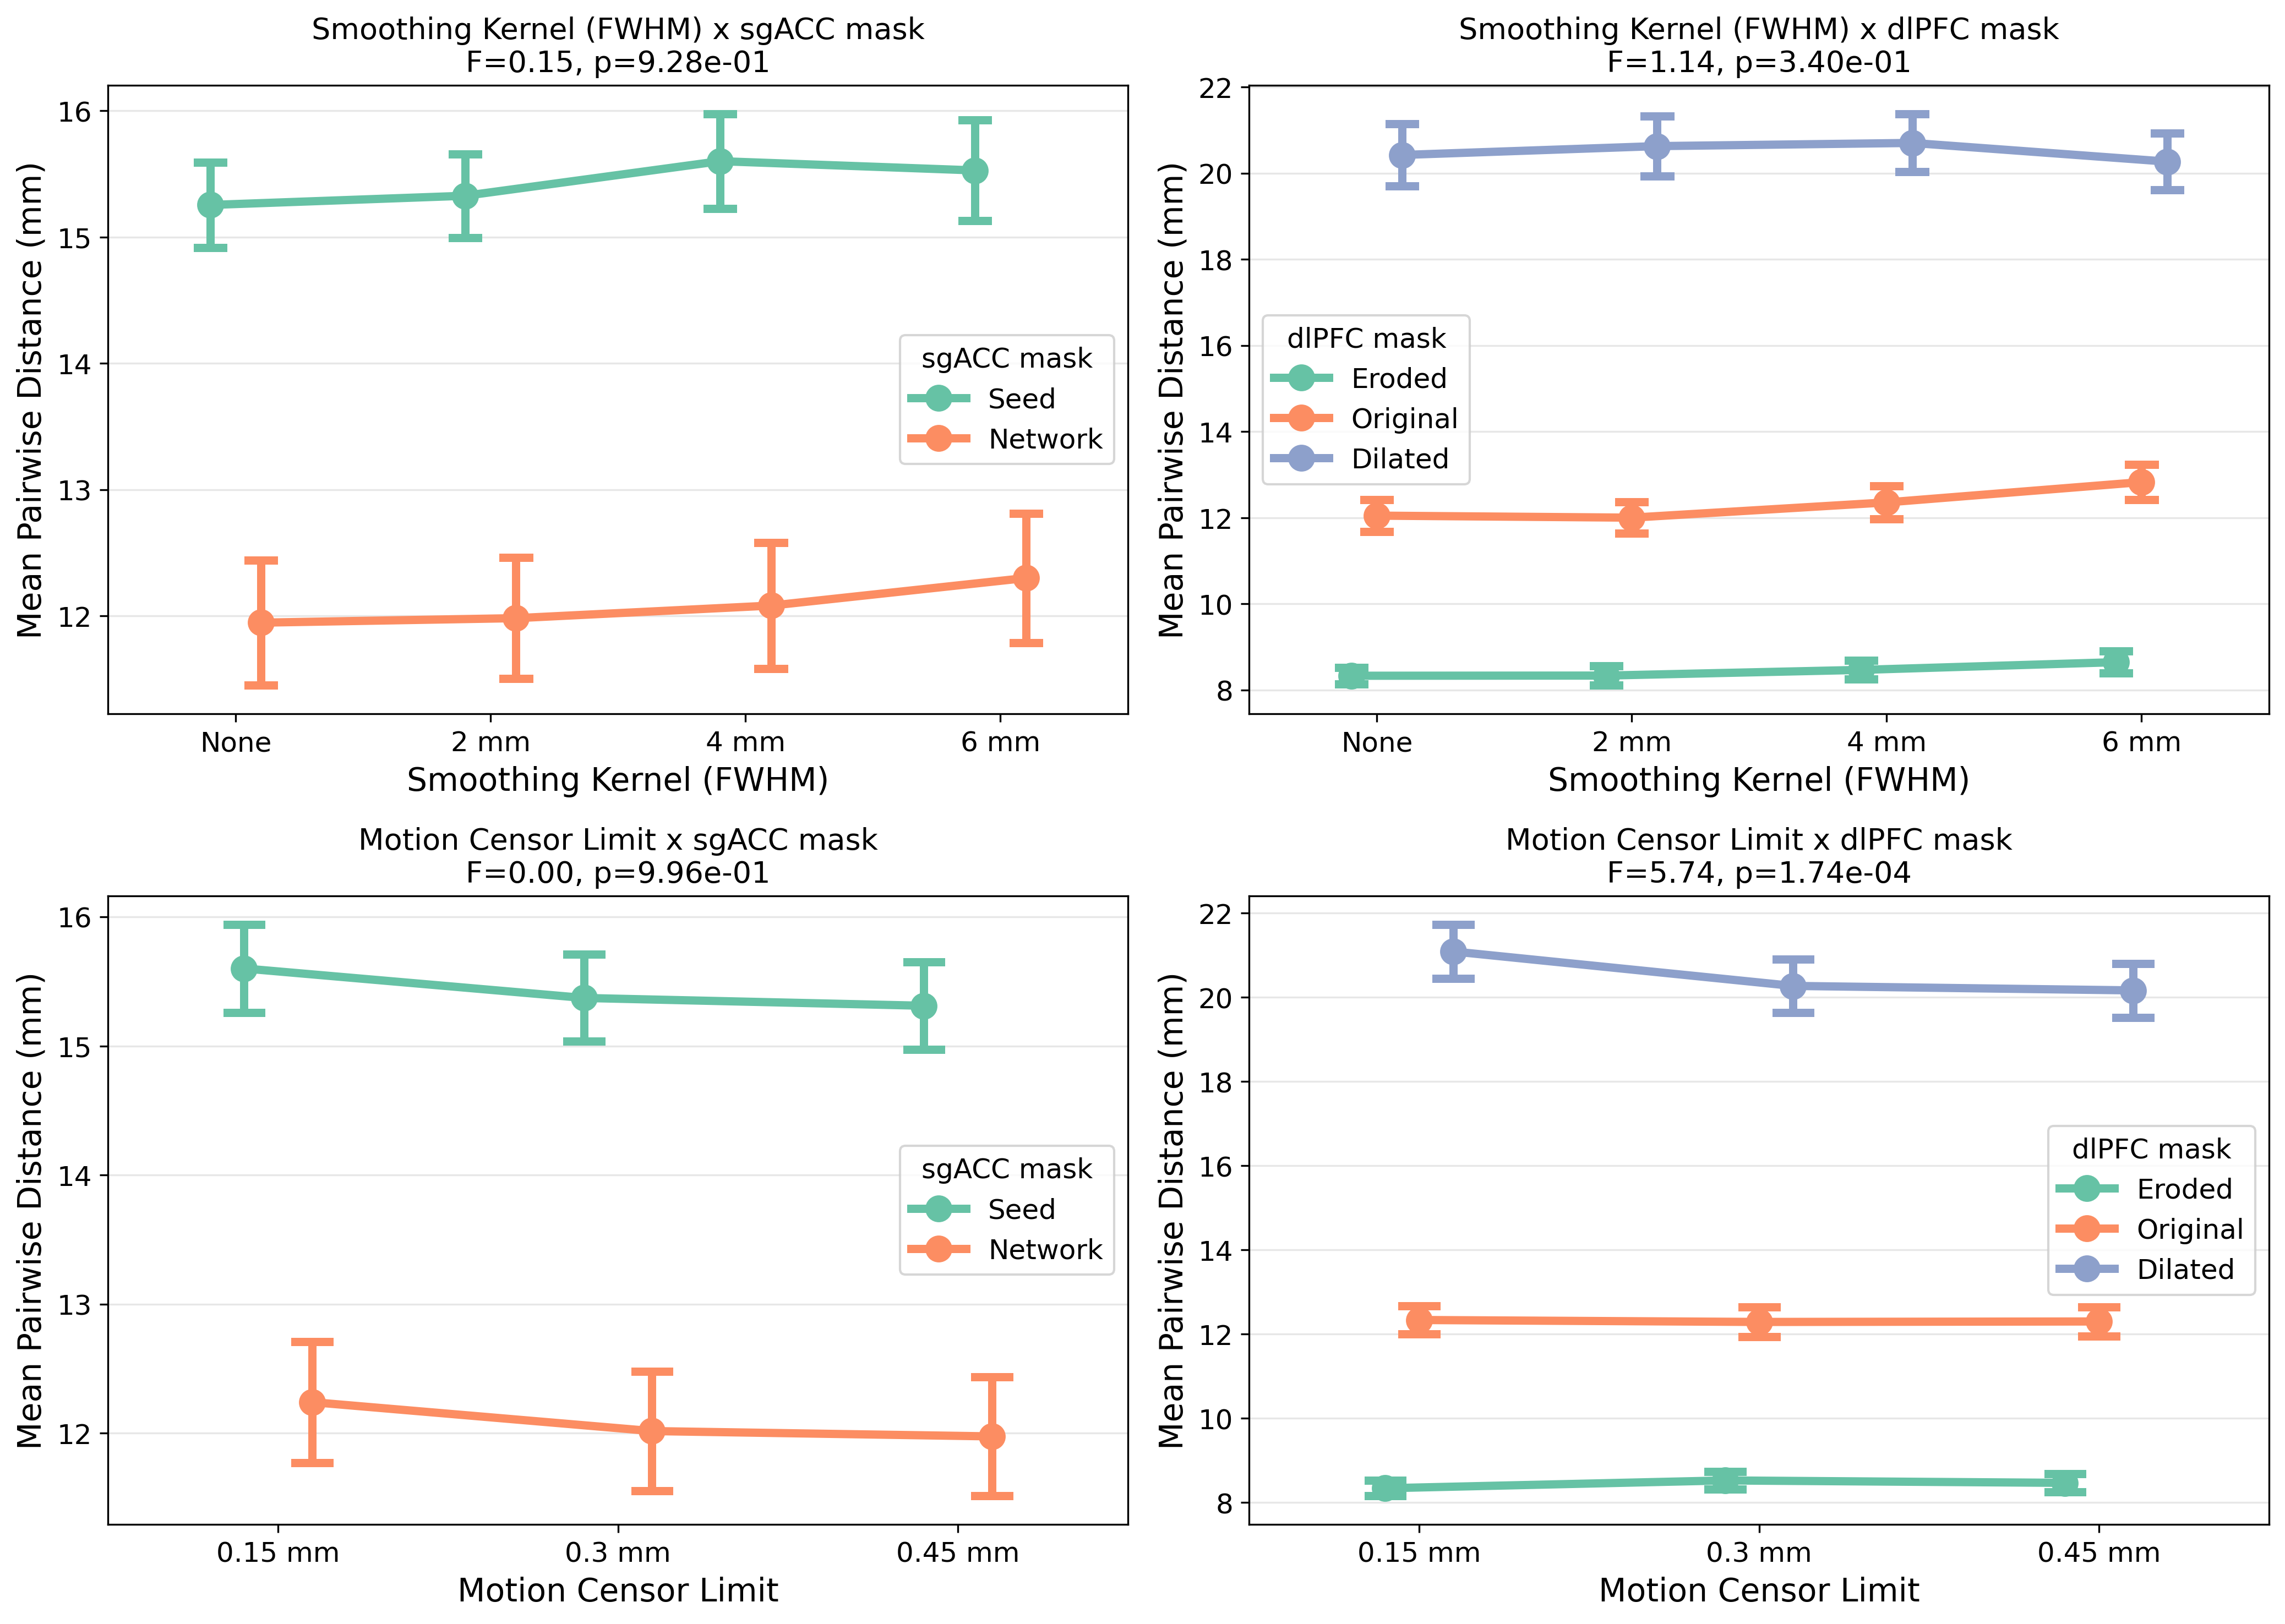

In [15]:
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

for row, gridVar in enumerate(gridVars):
    for col, otherVar in enumerate(['target', 'clustMask']):
        aggd = combodf.groupby(['subject', gridVar, otherVar])['mean_distance'].mean().reset_index()
        ax = axes[row, col]
        sns.pointplot(data=aggd, x=gridVar, y='mean_distance', hue=otherVar, order=orderDict[gridVar],
                      hue_order=orderDict[otherVar], palette='Set2', errorbar='se', dodge=0.2,
                      capsize=0.1, ax=ax)
        ax.set_xticks(range(len(orderDict[gridVar])), nameDict[gridVar])
        handles, _ = ax.get_legend_handles_labels()
        ax.legend(handles, nameDict[otherVar], title=varNameDict[otherVar])

        term = f'{gridVar}:{otherVar}'
        ax.set_title(f"{varNameDict[gridVar]} x {varNameDict[otherVar]}\n"
                     f"F={fourway_table.loc[term, 'F Value']:.2f}, p={fourway_table.loc[term, 'Pr > F']:.2e}",
                     fontsize=13)
        ax.set_xlabel(varNameDict[gridVar])
        ax.set_ylabel(ylabel)

plt.tight_layout()
plt.savefig(os.path.join(output_dir, 'Interaction_grid_x_main.svg'))
plt.show()

### Export statistics to file

In [16]:
stats_path = os.path.join(output_dir, 'stats_paramGrid.txt')

def write_pairwise(f, pairwise, indent='  '):
    f.write(f'{indent}{PAIRWISE_HEADER}\n')
    f.write(indent + '-' * len(PAIRWISE_HEADER) + '\n')
    for p in pairwise:
        f.write(f'{indent}{format_pairwise(p)}\n')

with open(stats_path, 'w') as f:
    f.write('Parameter Grid Statistical Results Summary\n')
    f.write(f"Data: {dataFile}, sign = '{peakSign}', matchSessions = {matchSessions}\n")
    f.write(f"N subjects: {combodf['subject'].nunique()}\n")
    f.write(f"Sessions per cell: {combodf['n_sessions'].value_counts().sort_index().to_dict()}\n")
    f.write('=' * 90 + '\n\n')

    # --- Main effects ---
    f.write('MAIN EFFECTS (one-way, averaged over other factors)\n')
    f.write('=' * 90 + '\n\n')
    for var in gridVars:
        r = stat_results[var]
        f.write(f"Variable: {varNameDict[var]} ({var})\n")
        f.write(f"Groups: {[f'{g:g}' for g in r['groups']]}\n")
        f.write(f"{r['stat_name']} = {r['stat']:.4f}, p = {r['p_val']:.2e}\n")
        f.write('\nGroup descriptives:\n')
        for g in r['groups']:
            vals = agg_dfs[var][agg_dfs[var][var] == g]['mean_distance']
            f.write(f"  {g:<8g}: mean={vals.mean():.3f}, SD={vals.std(ddof=1):.3f}, n={len(vals)}\n")
        if r['pairwise']:
            f.write(f"\nPost-hoc paired t-tests (Bonferroni corrected, k={len(r['pairwise'])}):\n")
            write_pairwise(f, r['pairwise'])
        f.write('\n' + '=' * 90 + '\n\n')

    # --- Factorial models ---
    for label, table in [('2-WAY REPEATED MEASURES ANOVA (fwhm x motion)', twoway_table),
                         ('4-WAY REPEATED MEASURES ANOVA (fwhm x motion x target x clustMask)', fourway_table)]:
        f.write(label + '\n')
        f.write('=' * 90 + '\n\n')
        f.write(table.to_string())
        f.write('\n\n')
        sig_effects = table[table['Pr > F'] < 0.05]
        if len(sig_effects) > 0:
            f.write('Significant effects (p < 0.05):\n')
            for effect_name, row in sig_effects.iterrows():
                f.write(f"  {effect_name}: F={row['F Value']:.4f}, p={row['Pr > F']:.2e}\n")
        else:
            f.write('No significant effects at p < 0.05.\n')
        f.write('\n' + '=' * 90 + '\n\n')

    # --- Simple effects ---
    f.write('SIMPLE EFFECTS (one-way within each level of the other grid factor)\n')
    f.write('=' * 90 + '\n\n')
    for (testVar, splitVar, level), r in simple_results.items():
        f.write(f"{testVar} | {splitVar} = {level:g}: {r['stat_name']} = {r['stat']:.4f}, p = {r['p_val']:.2e}\n")
        if r['pairwise']:
            write_pairwise(f, r['pairwise'], indent='    ')
        f.write('\n')
    f.write('=' * 90 + '\n')

print(f'Statistics saved to {stats_path}')

Statistics saved to output\paramGrid\stats_paramGrid.txt
